<a href="https://colab.research.google.com/github/kokilahemachandra-afk/srilanka-ntl-midterm/blob/main/notebooks/06_convergence_clubs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 · Convergence clubs: one path or several?

β-convergence (notebook 03) asks whether dimmer divisions grow faster **on average**.
It can hide a different pattern: groups of divisions each heading to **their own
level** ("clubs"), with gaps between groups that never close.

The **Phillips–Sul (2007) log t test** checks this:
1. Do all 339 divisions share one common path? If yes: overall convergence.
2. If not, it sorts divisions into clubs whose members converge among themselves.

Variable: light per km² (`ntl_mean`), 2014–2025, as in notebook 03.

**Setup**

In [ ]:
!pip install -q geo4bolivia
import pandas as pd, numpy as np, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import geo4bolivia as geo

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
REPO = "https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/"
annual = pd.read_csv(REPO + "data/processed/lka_ds339_ntl_annual.csv")
shp = gpd.read_file(REPO + "data/boundaries/lka_admin3.shp")
gdf = shp.rename(columns={"adm3_pcode": "geo_id", "adm3_name": "name"})[["geo_id", "name", "geometry"]]

## Step C1 · Rescale so that all logs are positive

The test divides each division's log light by the national average of log light.
Most `ntl_mean` values are below 1, so their logs are **negative**. As lights grow,
the national average of the logs passes through zero, and dividing by a number
near zero makes the paths explode. A first run without rescaling gave paths of
+27 and −9, which is meaningless.

**Fix:** multiply by 100 before taking logs (a change of units). Every log is then
positive. Step C4 checks that the main result does not depend on this choice.

In [ ]:
print("Smallest ntl_mean:", round(annual["ntl_mean"].min(), 3))                       # 0.076
print("Share of division-years with a negative log:",
      round((np.log(annual["ntl_mean"]) < 0).mean(), 2))                              # 0.77
annual["ntl_x100"] = annual["ntl_mean"] * 100
print("Smallest log after rescaling:", round(np.log(annual["ntl_x100"]).min(), 2))    # 2.03 (positive)

Smallest ntl_mean: 0.076
Share of division-years with a negative log: 0.77
Smallest log after rescaling: 2.03


## Step C2 · Run the test

- **Global test:** t below −1.65 means "no single common path" (5% level).
- **Clubs:** each club's own test should have t above −1.65 (its members converge).
- Settings are the package defaults: each division's Hodrick–Prescott trend
  (λ = 400) is used, which removes year-to-year noise, and the first 30% of years
  are trimmed from the regression.

In [ ]:
clubs = geo.convergence_clubs(annual, "ntl_x100", first=2014, last=2025, log=True, gdf=gdf)
print("Global log t test: t =", round(clubs.global_tstat, 2), "| one common path:", clubs.converged)  # −5.89, False
clubs.summary[["club", "n_members", "beta", "tstat", "converging"]].round(2)

Global log t test: t = -5.89 | one common path: False


,club,n_members,beta,tstat,converging
0,Club 1,11,0.04,0.56,True
1,Club 2,149,-0.10,-1.44,True
2,Club 3,177,0.21,2.29,True
3,Divergent,2,-0.68,-17.55,False


## Step C3 · Who is in each club?

In [ ]:
labels = {1: "Club 1", 2: "Club 2", 3: "Club 3", 0: "No club"}
mem = clubs.membership[["geo_id", "club"]].merge(
    annual[annual["year"] == 2025][["geo_id", "name", "province", "ntl_mean"]], on="geo_id")
mem["club_name"] = mem["club"].map(labels)
mem.to_csv("clubs_membership.csv", index=False)

print(mem.groupby("club_name")["ntl_mean"].agg(divisions="count", median_2025="median").round(2))
# The brightest groups, by name
mem[mem["club"].isin([0, 1])].sort_values("ntl_mean", ascending=False)[
    ["name", "province", "club_name", "ntl_mean"]].round(1)

           divisions  median_2025
club_name                        
Club 1            11         9.98
Club 2           149         1.14
Club 3           177         0.55
No club            2        33.02


,name,province,club_name,ntl_mean
0,Colombo,Western,No club,41.2
1,Thimbirigasyaya,Western,No club,24.8
5,Dehiwala,Western,Club 1,15.9
4,Sri Jayawardanapura Kotte,Western,Club 1,15.1
8,Kelaniya,Western,Club 1,14.1
6,Ratmalana,Western,Club 1,13.0
2,Kolonnawa,Western,Club 1,11.7
7,Negombo,Western,Club 1,10.0
3,Maharagama,Western,Club 1,9.1
10,Kattankudy,Eastern,Club 1,8.8


In [ ]:
pd.crosstab(mem["province"], mem["club_name"])

club_name,Club 1,Club 2,Club 3,No club
province,,,,
Central,0,12,29,0
Eastern,3,23,18,0
North Central,0,9,20,0
North Western,0,25,21,0
Northern,1,31,2,0
Sabaragamuwa,0,1,28,0
Southern,0,23,27,0
Uva,0,1,25,0
Western,7,24,7,2


## Step C4 · Does the result depend on the rescaling?

Rerun with three scales (× 100, × 1,000, × 10,000) and compare.
This takes a few minutes.

In [ ]:
rob = {}
for k in [100, 1000, 10000]:
    annual["v"] = annual["ntl_mean"] * k
    c = geo.convergence_clubs(annual, "v", first=2014, last=2025, log=True, draw_map=False)
    top = set(c.membership.loc[c.membership["club"] == 1, "geo_id"])
    rob[f"× {k}"] = {"global t": round(c.global_tstat, 2),
                     "club sizes (last = no club)": c.summary["n_members"].tolist(),
                     "same Club 1 as × 100": top == set(mem.loc[mem["club"] == 1, "geo_id"])}
robust = pd.DataFrame(rob).T
robust.to_csv("clubs_robustness.csv")
robust

,global t,club sizes (last = no club),same Club 1 as × 100
× 100,-5.89,"[11, 149, 177, 2]",True
× 1000,-8.3,"[11, 66, 260, 2]",True
× 10000,-9.62,"[11, 34, 90, 202, 2]",True


## Step C5 · Map and paths

**Map:** where each club is. **Paths:** each club's average *relative transition
path*, its log light relative to the national average (1 = average). A club line
moving toward 1 is catching up to (or down to) the average; a flat line keeps its
distance.

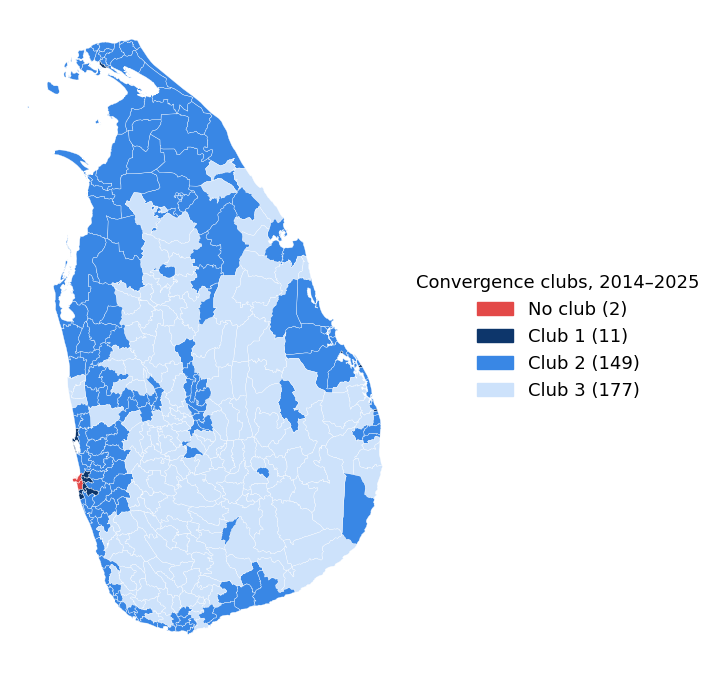

In [ ]:
gplot = gdf.copy()
gplot["geometry"] = gdf.to_crs(5235).simplify(150).to_crs(4326)
cm = gplot.merge(mem[["geo_id", "club_name"]], on="geo_id")
colours = {"No club": "#e34948", "Club 1": "#0d366b", "Club 2": "#3987e5", "Club 3": "#cde2fb"}
counts = cm["club_name"].value_counts()

fig, ax = plt.subplots(figsize=(8, 8.5))
cm.plot(color=cm["club_name"].map(colours), edgecolor="white", linewidth=0.25, ax=ax)
ax.set_axis_off()
# Place the legend on the right side of the map using bbox_to_anchor
ax.legend(handles=[Patch(color=colours[k], label=f"{k} ({counts.get(k, 0)})") for k in colours],
          title="Convergence clubs, 2014–2025", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.savefig("fig_clubs_map.png", dpi=200, bbox_inches="tight")
plt.show()

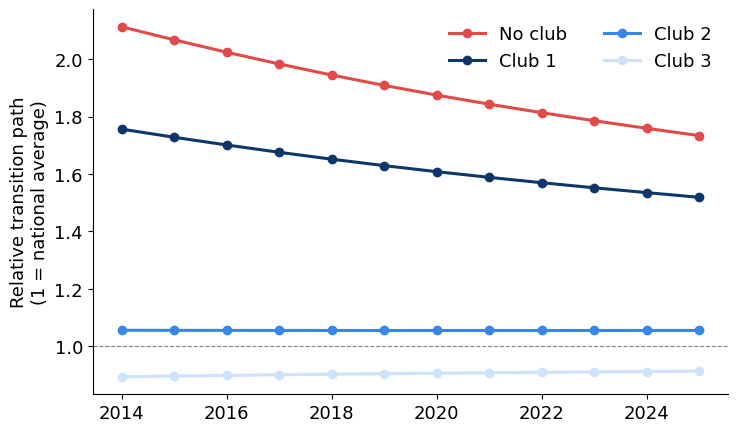

club_name,Club 1,Club 2,Club 3,No club
year,,,,
2014,1.76,1.06,0.89,2.11
2025,1.52,1.06,0.91,1.73


In [ ]:
paths = clubs.df[["geo_id", "year", "relative"]].merge(mem[["geo_id", "club_name"]], on="geo_id")
avg = paths.groupby(["club_name", "year"])["relative"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(8.2, 5.0))
for k in ["No club", "Club 1", "Club 2", "Club 3"]:
    ax.plot(avg.index, avg[k], marker="o", lw=2.2, color=colours[k], label=k)
ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.set_ylabel("Relative transition path\n(1 = national average)")
ax.set_xticks(range(2014, 2026, 2))
ax.legend(frameon=False, ncols=2)
plt.savefig("fig_clubs_paths.png", dpi=200, bbox_inches="tight")
plt.show()
avg.round(2).iloc[[0, -1]]

**Results**
- **No single common path:** the global test rejects overall convergence
  (t = −5.89, and −8.3 to −9.6 at other scales).
- **A stable bright core:** at every scale the same **11 divisions** form Club 1:
  seven around Colombo (Dehiwala, Kotte, Kelaniya, Ratmalana, Kolonnawa, Negombo,
  Maharagama) and four dense towns elsewhere (Jaffna; Kattankudy, Eravur Town and
  Sainthamaruthu in the East). **Colombo and Thimbirigasyaya**, the two brightest
  divisions, follow paths of their own (no club).
- **The bright groups are moving toward the average** (relative path 2.11 → 1.73
  for Colombo/Thimbirigasyaya and 1.76 → 1.52 for Club 1), consistent with
  β-convergence.
- **The rest do not converge into one group:** they stay in separate clubs with
  flat, parallel paths. Club 3 (177 divisions at × 100) is concentrated in Uva,
  Sabaragamuwa, Central and North Central. **How this large group splits depends
  on the scale** (2 clubs at × 100 and × 1,000, 3 at × 10,000), so only the
  bright-core result is robust.

**Interpretation:** the catching up in notebook 03 mostly reflects the brightest
urban divisions moving toward the average, not dim divisions joining them. As
before, this is convergence **in light** (see notebook 04).

In [ ]:
from google.colab import files
for f in ["clubs_membership.csv", "clubs_robustness.csv", "fig_clubs_map.png", "fig_clubs_paths.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>